## Реализация Double DQN с буфером памяти в PyTorch

Реализуем метод обучения Double DQN с буфером памяти и **двумя ИНС** с одинаковой структурой:
            
1. обучаемая Q-функция $\widehat q(s,a,\theta)$, её параметры будем настраивать, 
2. целевая Q-функция $\widehat q(s,a,\theta^{-})$ используется для формирования целей обновления.

Для генерации траектории будем использовать $\varepsilon$-жадную стратегию на основе текущих значений обучаемой Q-функции. Цель обновления формируется на основе перехода $(s,a,r,s', terminated)$ в виде 

$$r + \gamma (1-terminated) \max_a \widehat q(s',a,\theta^{-}),$$

В переменной $terminated$ хранится флаг об окончании эпизода, если он равен 1, то целью обновления является просто полученное вознаграждение $r$, так как терминальные состояния имеют по умолчанию ценность 0.
Для приближения к этой цели обновляются веса у обучаемой ИНС. Вторая сеть копирует веса первой после нескольких итераций обучения первой сети.

Для большей устойчивости метода градиентного спуска, обучение необходимо проводить не по одному шагу по траектории, а пакетом. Для этого нужен буфер с памятью для опыта, генерируемого по поведенческой стратегии, который сохраняет строку данных вида $(s,a,r,s',terminated)$. В ходе шага обучения из этого буфера выбирается случайным образом набор строчек, формируются обучающие данные и на этих данных обучается первая ИНС.

Буфер имеет фиксированный размер. Когда буфер заполнен, то при помещении в него новых строчек старые строки удаляются (иными словами, буфер представляет собой очередь). Использование пакета данных из буфера памяти позволяет ещё и декоррелировать обучающие данные.

Итоговая функция ошибки, минимизацию которой нужно провести на каждом шаге обновления параметров обучаемой ИНС, имеет вид

$$
J(\theta_k) = \frac 1 N \sum_{i=1}^N [r_i + \gamma (1-terminated_i)  \max_a \widehat q(s'_i,a,\theta^{-}) - \widehat q(s_i,a_i,\theta_k)]^2,
$$
где $(s_i, a_i, r_i, s_i', terminated_i)$, $i=1,...,N$, это выборка из буфера памяти. 
Шаг градиентного спуска имеет вид:

$$
\theta_{k+1} = \theta_k + \alpha \frac 1 N \sum_{i=1}^N [r_i + \gamma  (1-terminated_i) \max_a \widehat q(s'_i,a,\theta^{-}) - \widehat q(s_i,a_i,\theta_k)] \, grad_\theta \widehat q(s_i,a_i,\theta_k)
$$



In [1]:
import os 
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"
# для избежания ошибки при отрисовки графиков
#https://programmerah.com/solved-omp-error-15-initializing-libiomp5md-dll-but-found-libiomp5md-dll-already-initialized-35360/

In [2]:
# Импорт нужных пакетов
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import random
import time
from collections import deque

from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

Как и для метода Vanilla DQN, агент будет получать теперь уже два экземпляра класса, зазадющего ИНС, при создании агента. 

Реализуем класс для хранения полученного опыта ReplayBuffer на основе такой структуры данных, как очередь. В этом классе реализуем методы

    add(state, action, reward, next_state, done) - сохранить строку данных (s,a,r,s',done) в буфере памяти
    
    sample(batch_size) - вернуть batch_size строчек из массива с опытом, строки выбираются случайно. В строке
    states, actions, rewards, next_states, dones.
    
    len(exp_replay) - возвращает число элементов в буфере.
    
Метод `sample()` будет ещё дополнительно приводить данные к  типу данных Tensor, чтобы данные можно было напрямую использовать для обучения ИНС. Также в методе  `sample()` будем перемещать данные на `device`, где будет проходить обучение ИНС.

In [3]:
def data_to_tensors(state, action, reward, next_state, terminated): 
    # перевод данных в тензоры
    state = torch.as_tensor(state, dtype=torch.float32)
    action = torch.as_tensor(action, dtype=torch.long) # будет использоваться как индекс
    reward = torch.as_tensor(reward, dtype=torch.float32)
    next_state = torch.as_tensor(next_state, dtype=torch.float32)
    terminated = torch.as_tensor(terminated, dtype=torch.float32)
    # флаги переводим в float, а не в целые, так как done используется в вычислениях
    
    return state, action, reward, next_state, terminated

class ReplayBuffer:
    def __init__(self, size):
        self.size = size  # максимальное число элементов
        self.buffer = deque(maxlen=size)  
        
    def __len__(self):
        return len(self.buffer)

    def add(self, state, action, reward, next_state, terminated):
        item = data_to_tensors(state, action, reward, next_state, terminated)
        self.buffer.append(item)

    def sample(self, batch_size):
        samples = random.sample(self.buffer, k=batch_size)
        # из samples выбрать отдельно состояния, действия, вознаграждения, новые состояния
        # zip выдаёт тип zip, затем приведение к списку
        states, actions, rewards, next_states, terminates = tuple(zip(*samples))
        # получим список состояний, действий и т.д.    
        states = torch.stack(states).to(device)
        actions = torch.stack(actions).to(device)
        rewards = torch.stack(rewards).to(device)
        next_states = torch.stack(next_states).to(device)
        terminates = torch.stack(terminates).to(device)
    
        return states, actions, rewards, next_states, terminates   

Далее, напишем класс DQN-агента. Для этого зададим набор гиперпараметров.

In [4]:
BUFFER_SIZE = int(1e5)  # размер буфера памяти
BATCH_SIZE = 64         # размер пакета
UPDATE_EVERY = 4        # как часто проводить обучение сети
UPDATE_EVERY_Q = 50     # как часто обновлять параметры целевой сети

In [5]:
class DQNAgent():

    def __init__(self, env, model, model_target, alpha=0.001, gamma=0.99, epsilon=0.1, hard_update = True, tau = 1e-3):
        # инициализация полей
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = torch.tensor(gamma).float().to(device)
        self.nA = env.action_space.n
        # Новые поля
        self.hard_update = hard_update
        self.tau = tau #коэффициент для мягкого обновления параметров целевой сети        

        # инициализация сетей
        self.Q_train = model
        self.Q_target = model_target
        self.optimizer = torch.optim.Adam(self.Q_train.parameters(), lr=self.alpha)

        # буфер памяти
        self.memory = ReplayBuffer(BUFFER_SIZE)
        # счётчик, для определения момента обновления параметров сети
        self.t_step = 0

    def best_action(self, state):
        # состояние в тензор
        state = torch.tensor(state).float().to(device)
        # вычисляем отклик ИНС, используем torch.no_grad(), чтобы не вычислялись градиенты  
        with torch.no_grad():
            q_values = self.Q_train(state)
        # жадный выбор
        return torch.argmax(q_values).cpu().item() 
        
    def get_action(self, state):
        if np.random.rand() < self.epsilon:
            return np.random.choice(self.nA)
        return self.best_action(state)
    
    def update(self, state, action, reward, next_state, done):
        # Сохранить строку данных (s,a,r,s',done) в буфер
        self.memory.add(state, action, reward, next_state, done)        
        
        self.t_step = self.t_step + 1
        # обучаться каждые UPDATE_EVERY шагов.
        if self.t_step  % UPDATE_EVERY == 0:
            #  если в памяти достаточно много сэмплов, то обучаться
            if len(self.memory) > BATCH_SIZE:
                self.learn()

    def learn(self):
        # получаем данные из буфера
        states, actions, rewards, next_states, dones = self.memory.sample(BATCH_SIZE)

        # Находим max Q_2(s,a), вычисляем отклик второй ИНС без обучения, 
        with torch.no_grad():
            q_next_states = agent.Q_target(next_states)
        # вычисляем целевые значения для обучения первой ИНС (max в каждой строке, затем выбор значений)
        q_targets_next = q_next_states.max(1)[0]
        q_targets = rewards + self.gamma * q_targets_next * (1 - dones)
        # Обучение: находим отклики первой ИНС на пакет состояний
        # из каждой строки [Q(s,a1), Q(s,a2),...] выбираем Q(s,a) в соответствии с фактическими сделанными действиями
        q_expected = agent.Q_train(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        
        # функция ошибки и шаг градиентного спуска
        loss = F.mse_loss(q_expected, q_targets)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # обновить целевую сеть
        self.update_Qtarget(agent.hard_update)

    
    # обновление параметров целевой ИНС
    def update_Qtarget(self, hard_update = True):
        if hard_update:
            if self.t_step % UPDATE_EVERY_Q == 0:
                agent.Q_target.load_state_dict(agent.Q_train.state_dict())
        else:
            for target_param, trained_param in zip(agent.Q_target.parameters(), agent.Q_train.parameters()):
                target_param.data.copy_(self.tau*trained_param.data + (1.0-self.tau)*target_param.data)

    def play(self, env, n_episodes):
        for episode in tqdm(range(n_episodes)):
            state, _ = env.reset()
            while True:
                # выбираем действия по стратегии
                action = agent.best_action(state)
                state, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    break
                
    def save_model(self, fname):
        torch.save(self.Q_target, 'savedModels/'+str(fname)+'.pkl')
        print("Net saved to: ", 'savedModels/'+str(fname)+'.pkl')
        
    def load_model(self, fname):
        self.Q_train = torch.load(fname, map_location=torch.device('cpu'), weights_only=False).to(device)
        self.Q_target = torch.load(fname, map_location=torch.device('cpu'), weights_only=False).to(device)
        self.Q_train.eval()
        self.Q_target.eval()
        print("Model loaded")

В методе `update_Qtarget()`, которая занимается обновлением параметров целевой ИНС, мы либо просто копируем веса из обучаемой ИНС в целевую, либо производим так называемое мягкое обновление (англ. soft update). Суть его в следующем: пусть $\theta_{target}$ параметры целевой ИНС, $\theta_{train}$ параметры обучаемой ИНС. Тогда мягкое обновление происходит по правилу
$$ \theta_{target} = \tau * \theta_{train} + (1-\tau) * \theta_{target}.$$
Число $\tau$ от 0 до 1, и он отвечает за скорость постепенного изменения параметров целевой ИНС.

Теперь напишем управляющий алгоритм для метода DQN.

In [6]:
def DQN_control(env, agent, num_episodes=10000, 
                      eps_start=1.0, eps_decay = 0.995, eps_min = 0.01,
                       goal_score=200):
    # Инициализация   
    agent.epsilon = eps_start
    start_time = time.time()  # счётчик времени выполнения
    running_gain = goal_score - 1
    
    for i in range(num_episodes):
        state, _ = env.reset()
        
        # запускаем эпизод взаимодействия со средой        
        while True:
            action = agent.get_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            agent.update(state, action, reward, next_state, terminated)
            state = next_state
            if terminated or truncated:
                break
        
        # Снижение eps и alpha
        agent.epsilon = max(agent.epsilon * eps_decay, eps_min)
        
        if i % 50 ==0:
            running_gain = np.mean(np.array(env.return_queue)[-100:])
            print("\rДоход: {:.2f} в эпизоде {}".format(running_gain, i))
            print("--- {} сек ---".format(time.time() - start_time))
            start_time = time.time()

        # выход из цикла при достижении целевого среднего дохода
        if running_gain > goal_score:  
            print("Успех на эпизоде {}!".format(i))
            # поместить в целевую сеть итоговые веса
            agent.update_Qtarget(hard_update = True)
            break   

# Пример 1

Сначала рассмотрим работу метода DQN на примере задачи об обратном маятнике.

In [7]:
env = gym.make('CartPole-v1')
env = gym.wrappers.RecordEpisodeStatistics(env,2000)

print('Размерность вектора состояний: ', env.observation_space.shape[0])
print('Количество действий: ', env.action_space.n)

Размерность вектора состояний:  4
Количество действий:  2


Формируем структуру сети и создаём два экзампляра. Используем ИНС с 1 слоем шириной 64 нейрона.

In [8]:
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        #self.seed = torch.manual_seed(seed)
        self.fc1 = nn.Linear(state_size, 64)
        self.fc2 = nn.Linear(64, action_size)
        
    def forward(self, state):
        x = self.fc1(state)
        x = F.relu(x)
        return self.fc2(x)
    
model = QNetwork(env.observation_space.shape[0], env.action_space.n).to(device)
model_target = QNetwork(env.observation_space.shape[0], env.action_space.n).to(device)

# Гиперпараметры
BUFFER_SIZE = int(1e5)  # размер буфера памяти
BATCH_SIZE = 64         # размер пакета
UPDATE_EVERY = 4        # как часто проводить обучение сети
UPDATE_EVERY_Q = 50     # как часто обновлять параметры целевой сети

Задаём гиперпараметры, создаём агента.

In [9]:
env = gym.make('CartPole-v1')
env = gym.wrappers.RecordEpisodeStatistics(env,2000)

agent = DQNAgent(env, model, model_target)

In [10]:
state, _ = env.reset()
print(state)

agent.best_action(state)

[ 0.03801471 -0.03858037 -0.03086479 -0.00743642]


1

Проводим обучение.

In [11]:
DQN_control(env, agent, goal_score = 250);

Доход: 26.00 в эпизоде 0
--- 0.024838924407958984 сек ---
Доход: 21.20 в эпизоде 50
--- 1.1454145908355713 сек ---
Доход: 19.18 в эпизоде 100
--- 0.3331608772277832 сек ---
Доход: 19.13 в эпизоде 150
--- 0.41092348098754883 сек ---
Доход: 21.95 в эпизоде 200
--- 0.45728516578674316 сек ---
Доход: 29.72 в эпизоде 250
--- 0.7443461418151855 сек ---
Доход: 44.55 в эпизоде 300
--- 1.0828654766082764 сек ---
Доход: 58.75 в эпизоде 350
--- 1.38100266456604 сек ---
Доход: 70.37 в эпизоде 400
--- 1.5869033336639404 сек ---
Доход: 111.28 в эпизоде 450
--- 3.250523805618286 сек ---
Доход: 286.86 в эпизоде 500
--- 9.674532413482666 сек ---
Успех на эпизоде 500!


In [12]:
agent.save_model("DDQN_CartPole_64neurons")

Net saved to:  savedModels/DDQN_CartPole_64neurons.pkl


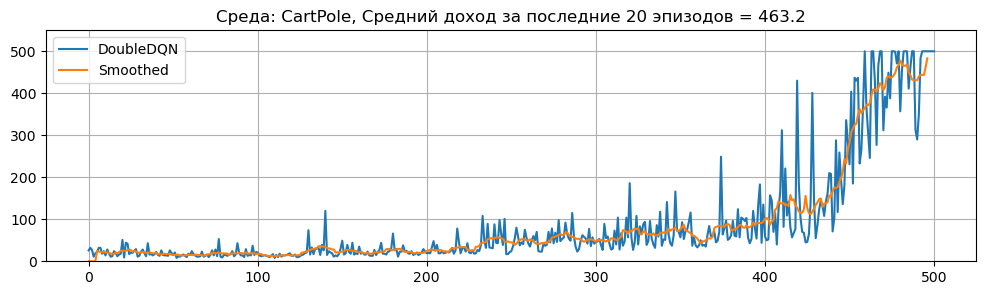

In [13]:
def plot_rewards(env_name, returns, label):
    # сглаженный вектор доходов
    returns_smoothed = np.pad(np.convolve(returns, np.ones(10)/10, mode='valid'),[5, 0])
    fig = plt.figure(figsize=(12, 3))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.plot(returns_smoothed, label="Smoothed")
    plt.grid()
    plt.legend()
    plt.ylim(0, 550)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("CartPole", returns, 'DoubleDQN')

Ниже можно запустить 100 эпизодов симуляции работы обученного агента.

In [11]:
# можно подгрузить обученные веса
agent = DQNAgent(env, model, model_target)
agent.load_model("savedModels/DDQN_CartPole_64neurons.pkl")

Model loaded


In [14]:
env = gym.make('CartPole-v1')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,100)

print("Средний доход: ", np.mean(env.return_queue))
print("Минимальный доход: ", np.min(env.return_queue))

100%|██████████| 100/100 [00:04<00:00, 20.49it/s]

Средний доход:  447.65
Минимальный доход:  345.0


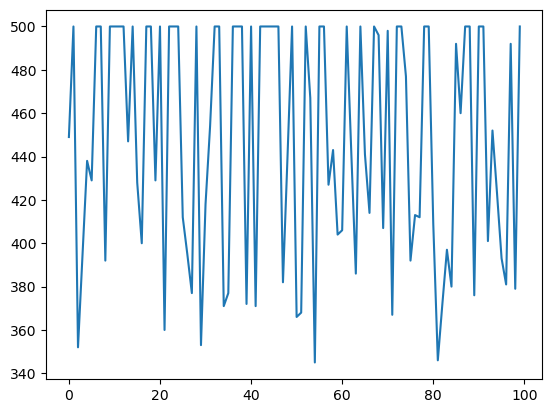

In [15]:
plt.plot(np.array(env.return_queue))

In [16]:
# демонстрация работы агента
env = gym.make('CartPole-v1', render_mode='human')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,1)
print("Число шагов:", env.return_queue[-1])

env.close()

  0%|          | 0/1 [00:00<?, ?it/s]D:\anaconda3\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
100%|██████████| 1/1 [00:12<00:00, 12.62s/it]

Число шагов: 500.0


# Пример 2

Рассмотрим задачу о посадке лунного модуля.

In [24]:
env = gym.make('LunarLander-v3')
env = gym.wrappers.RecordEpisodeStatistics(env,2000)

print('Размерность вектора состояний: ', env.observation_space.shape[0])
print('Количество действий: ', env.action_space.n)

Размерность вектора состояний:  8
Количество действий:  4


Поскольку в сравнении с задачей о маятнике, здесь вектор состояний больше и число действией больше, то используем сеть, где в скрытом слое 128 нейронов.


In [25]:
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        #self.seed = torch.manual_seed(seed)
        self.fc1 = nn.Linear(state_size, 128)
        self.fc2 = nn.Linear(128, action_size)
        
    def forward(self, state):
        x = self.fc1(state)
        x = F.relu(x)
        return self.fc2(x)
    
model = QNetwork(env.observation_space.shape[0], env.action_space.n).to(device)
model_target = QNetwork(env.observation_space.shape[0], env.action_space.n).to(device)

# Гиперпараметры
BUFFER_SIZE = int(1e5)  # размер буфера памяти
BATCH_SIZE = 64         # размер пакета
UPDATE_EVERY = 4        # как часто проводить обучение сети
UPDATE_EVERY_Q = 50     # как часто обновлять параметры целевой сети

In [26]:
env = gym.make('LunarLander-v3')
env = gym.wrappers.RecordEpisodeStatistics(env,2000)

agent = DQNAgent(env, model, model_target, alpha=0.003)

In [27]:
s, _ = env.reset()
print(s)

agent.get_action(s)

[-0.00741415  1.4154913  -0.75097716  0.20313229  0.0085978   0.17010736
  0.          0.        ]


2

In [28]:
gains = DQN_control(env, agent, goal_score = 200);

Доход: -88.03 в эпизоде 0
--- 0.02599167823791504 сек ---
Доход: -162.46 в эпизоде 50
--- 2.3262195587158203 сек ---
Доход: -139.78 в эпизоде 100
--- 3.003749370574951 сек ---
Доход: -118.38 в эпизоде 150
--- 4.509669065475464 сек ---
Доход: -112.48 в эпизоде 200
--- 6.218883037567139 сек ---
Доход: -113.06 в эпизоде 250
--- 10.512213706970215 сек ---
Доход: -113.94 в эпизоде 300
--- 17.69638967514038 сек ---
Доход: -92.84 в эпизоде 350
--- 25.227495908737183 сек ---
Доход: -73.87 в эпизоде 400
--- 26.281504154205322 сек ---
Доход: -51.29 в эпизоде 450
--- 26.072773933410645 сек ---
Доход: -9.49 в эпизоде 500
--- 22.852776288986206 сек ---
Доход: 10.43 в эпизоде 550
--- 17.820722341537476 сек ---
Доход: 18.59 в эпизоде 600
--- 20.617632627487183 сек ---
Доход: 24.86 в эпизоде 650
--- 21.917811632156372 сек ---
Доход: 78.74 в эпизоде 700
--- 20.22015357017517 сек ---
Доход: 165.62 в эпизоде 750
--- 18.164512395858765 сек ---
Доход: 177.96 в эпизоде 800
--- 15.852144479751587 сек ---
Дох

In [32]:
agent.save_model("DDQN_LunarLander_128neurons")

Net saved to:  savedModels/DDQN_LunarLander_128neurons.pkl


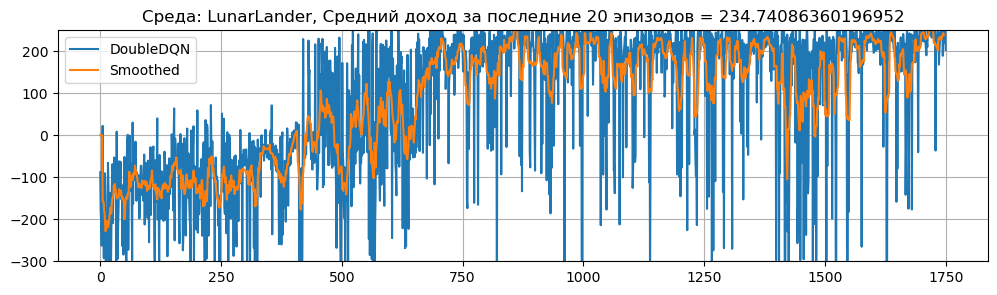

In [29]:
def plot_rewards(env_name, returns, label):
    # сглаженный вектор доходов
    returns_smoothed = np.pad(np.convolve(returns, np.ones(10)/10, mode='valid'),[5, 0])
    fig = plt.figure(figsize=(12, 3))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.plot(returns_smoothed, label="Smoothed")
    plt.grid()
    plt.legend()
    plt.ylim(-300, 250)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("LunarLander", returns, 'DoubleDQN')

In [33]:
# можно подгрузить обученные веса
agent = DQNAgent(env, model, model_target)
agent.load_model("savedModels/DDQN_LunarLander_128neurons.pkl")

Model loaded


Ниже можно запустить 100 эпизодов симуляции работы обученного агента.

100%|██████████| 100/100 [00:07<00:00, 13.82it/s]

Средний доход:  215.75189532302326
Минимальный доход:  -48.4084156796244


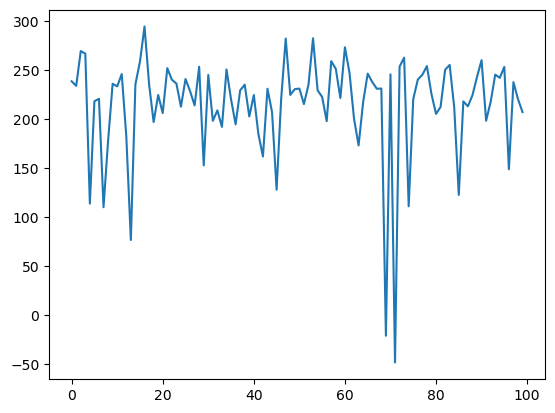

In [30]:
env = gym.make('LunarLander-v3')
env = gym.wrappers.RecordEpisodeStatistics(env)

gains = agent.play(env,100)

print("Средний доход: ", np.mean(env.return_queue))
print("Минимальный доход: ", np.min(env.return_queue))

plt.plot(np.array(env.return_queue))

Запуск симуляции с обученным агентом.

In [31]:
# создание экземпляра среды
env = gym.make('LunarLander-v3', render_mode='human')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,1)
print("Число шагов:", env.return_queue[-1])

env.close()

100%|██████████| 1/1 [00:07<00:00,  7.62s/it]

Число шагов: 264.2004681697743


### Пример 3.

Рассмотрим задачу о машинке и холме MountainCar. Структуру ИНС используем ту же самую.

In [42]:
env = gym.make('MountainCar-v0', max_episode_steps=500)
env = gym.wrappers.RecordEpisodeStatistics(env, 2000)

print('Размерность вектора состояний: ', env.observation_space.shape[0])
print('Количество действий: ', env.action_space.n)

Размерность вектора состояний:  2
Количество действий:  3


In [43]:
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        #self.seed = torch.manual_seed(seed)
        self.fc1 = nn.Linear(state_size, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, action_size)
        
    def forward(self, state):
        x = self.fc1(state)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        return self.fc3(x)
    
model = QNetwork(env.observation_space.shape[0], env.action_space.n).to(device)
model_target = QNetwork(env.observation_space.shape[0], env.action_space.n).to(device)

# Гиперпараметры
BUFFER_SIZE = int(1e5)  # размер буфера памяти
BATCH_SIZE = 64         # размер пакета
UPDATE_EVERY = 4        # как часто проводить обучение сети
UPDATE_EVERY_Q = 50     # как часто обновлять параметры целевой сети

In [44]:
agent = DQNAgent(env, model, model_target)

s, _ = env.reset()
print(s)

agent.get_action(s)

[-0.5881739  0.       ]


0

In [45]:
agent.epsilon

0.1

In [46]:
gains = DQN_control(env, agent, num_episodes=2500, eps_start=1.0, eps_decay = 0.999, eps_min= 0.00001, goal_score = -96);

Доход: -500.00 в эпизоде 0
--- 0.24067330360412598 сек ---
Доход: -500.00 в эпизоде 50
--- 12.29684853553772 сек ---
Доход: -500.00 в эпизоде 100
--- 12.21656584739685 сек ---
Доход: -500.00 в эпизоде 150
--- 13.006980419158936 сек ---
Доход: -500.00 в эпизоде 200
--- 13.160386562347412 сек ---
Доход: -500.00 в эпизоде 250
--- 13.830179929733276 сек ---
Доход: -500.00 в эпизоде 300
--- 13.636749982833862 сек ---
Доход: -500.00 в эпизоде 350
--- 13.68287444114685 сек ---
Доход: -500.00 в эпизоде 400
--- 13.487142086029053 сек ---
Доход: -500.00 в эпизоде 450
--- 13.874218225479126 сек ---
Доход: -500.00 в эпизоде 500
--- 14.218666315078735 сек ---
Доход: -500.00 в эпизоде 550
--- 14.234488725662231 сек ---
Доход: -500.00 в эпизоде 600
--- 14.30946660041809 сек ---
Доход: -499.13 в эпизоде 650
--- 14.341546535491943 сек ---
Доход: -498.08 в эпизоде 700
--- 14.486244440078735 сек ---
Доход: -474.17 в эпизоде 750
--- 13.225502967834473 сек ---
Доход: -385.58 в эпизоде 800
--- 9.21236467361

In [50]:
agent.save_model("DDQN_MountainCar_128_128neurons")

Net saved to:  savedModels/DDQN_MountainCar_128_128neurons.pkl


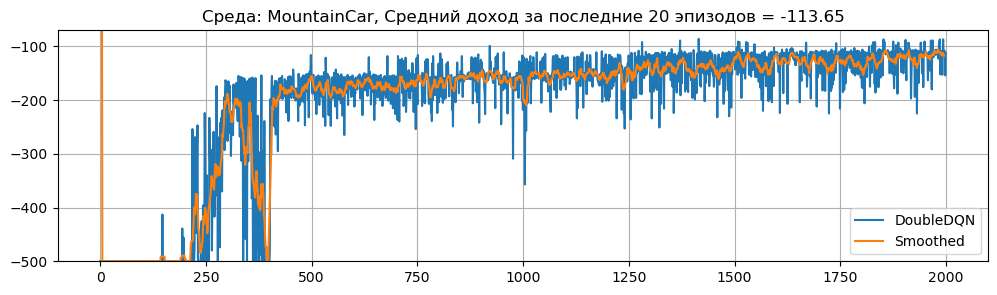

In [47]:
def plot_rewards(env_name, returns, label):
    # сглаженный вектор доходов
    returns_smoothed = np.pad(np.convolve(returns, np.ones(10)/10, mode='valid'),[5, 0])
    fig = plt.figure(figsize=(12, 3))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.plot(returns_smoothed, label="Smoothed")
    plt.grid()
    plt.legend()
    plt.ylim(-500, -70)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("MountainCar", returns, 'DoubleDQN')


In [51]:
agent.load_model("savedModels/DDQN_MountainCar_128_128neurons.pkl")

Model loaded


In [78]:
gains = DQN_control(env, agent, num_episodes=2000, eps_start=0.0001, eps_decay = 0.999, eps_min= 0.00001, goal_score = -96);

Доход: -98.25 в эпизоде 0
--- 0.08097124099731445 сек ---
Доход: -101.00 в эпизоде 50
--- 2.7166748046875 сек ---
Доход: -101.54 в эпизоде 100
--- 2.7551872730255127 сек ---
Доход: -102.21 в эпизоде 150
--- 2.704148530960083 сек ---
Доход: -101.09 в эпизоде 200
--- 2.5667407512664795 сек ---
Доход: -100.51 в эпизоде 250
--- 2.603635311126709 сек ---
Доход: -101.19 в эпизоде 300
--- 2.8909244537353516 сек ---
Доход: -101.55 в эпизоде 350
--- 2.6537625789642334 сек ---
Доход: -101.46 в эпизоде 400
--- 2.591498851776123 сек ---
Доход: -100.05 в эпизоде 450
--- 2.571545362472534 сек ---
Доход: -100.74 в эпизоде 500
--- 2.598076105117798 сек ---
Доход: -101.26 в эпизоде 550
--- 2.563608407974243 сек ---
Доход: -100.86 в эпизоде 600
--- 2.8853933811187744 сек ---
Доход: -100.99 в эпизоде 650
--- 2.595376968383789 сек ---
Доход: -100.55 в эпизоде 700
--- 2.5602920055389404 сек ---
Доход: -100.51 в эпизоде 750
--- 2.601707935333252 сек ---
Доход: -100.92 в эпизоде 800
--- 2.572222948074341 сек

100%|██████████| 100/100 [00:01<00:00, 59.22it/s]

Средний доход:  -102.19
Минимальный доход:  -107.0


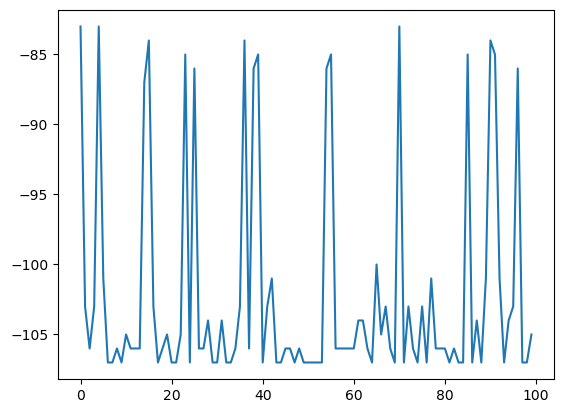

In [52]:
env = gym.make('MountainCar-v0')
env = gym.wrappers.RecordEpisodeStatistics(env)

gains = agent.play(env,100)

print("Средний доход: ", np.mean(env.return_queue))
print("Минимальный доход: ", np.min(env.return_queue))

plt.plot(np.array(env.return_queue))

In [49]:
# создание экземпляра среды
env = gym.make('MountainCar-v0', render_mode='human')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,1)
print("Число шагов:", env.return_queue[-1])

env.close()

100%|██████████| 1/1 [00:03<00:00,  3.85s/it]

Число шагов: -111.0


In [53]:
# Вычислим шаг дискретизации
lower_bounds = env.observation_space.low
upper_bounds = env.observation_space.high

pos_grid = np.linspace(lower_bounds[0], upper_bounds[0], 200)  # более мелкая сетка для сглаживания
vel_grid = np.linspace(lower_bounds[1], upper_bounds[1], 200)
X, Y = np.meshgrid(pos_grid, vel_grid)
Z = np.zeros_like(X, dtype=int)

    # Для каждой точки определяем лучшее действие
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        state = np.array([X[i, j], Y[i, j]])
        Z[i, j] = agent.best_action(state)

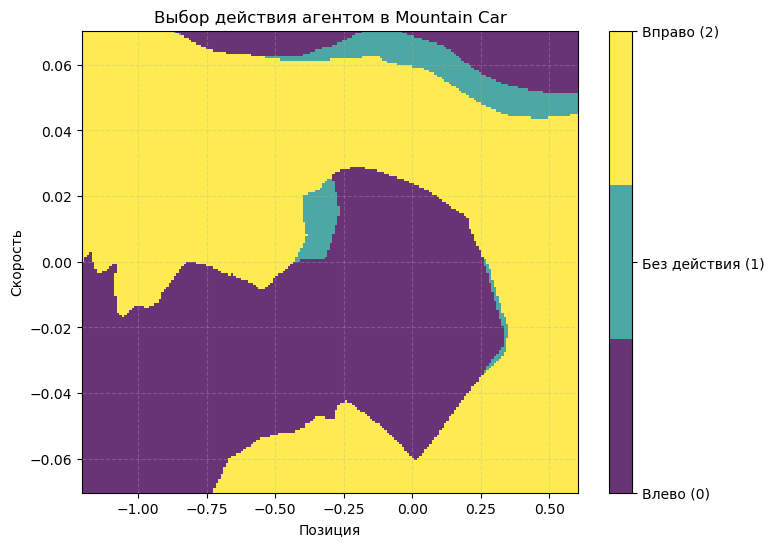

In [54]:
# Рисуем
plt.figure(figsize=(8, 6))
# Используем pcolormesh с дискретными цветами
cmap = plt.get_cmap('viridis', 3)  # три действия
mesh = plt.pcolormesh(X, Y, Z, cmap=cmap, shading='auto', alpha=0.8)
cbar = plt.colorbar(mesh, ticks=[0, 1, 2])
cbar.ax.set_yticklabels(['Влево (0)', 'Без действия (1)', 'Вправо (2)'])
plt.xlabel('Позиция')
plt.ylabel('Скорость')
plt.title('Выбор действия агентом в Mountain Car')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

Точный график оптимального решения

https://www.researchgate.net/publication/221226259_Classifier-Based_Policy_Representation

### Задача 

Реализовать для  модификацию метода DQN с приоритетным воспроизведением опыта. Сравнить обучение методом DQN с/без этой модификации.